                               Control fish  Caffeine fish
----------------------------------------------------------
Total distance (mm)                  5208.2         7527.0
Total distance (cm)                   520.8          752.7
Mean speed (mm/s)                      86.8          125.5
Max step per 0.01 s (mm)               13.7            6.7
x range (mm)                    -157 to 182    -110 to 192
y range (mm)                    -183 to 153      22 to 167
----------------------------------------------------------
Ratio (caffeine / control): 1.45  (45% farther)


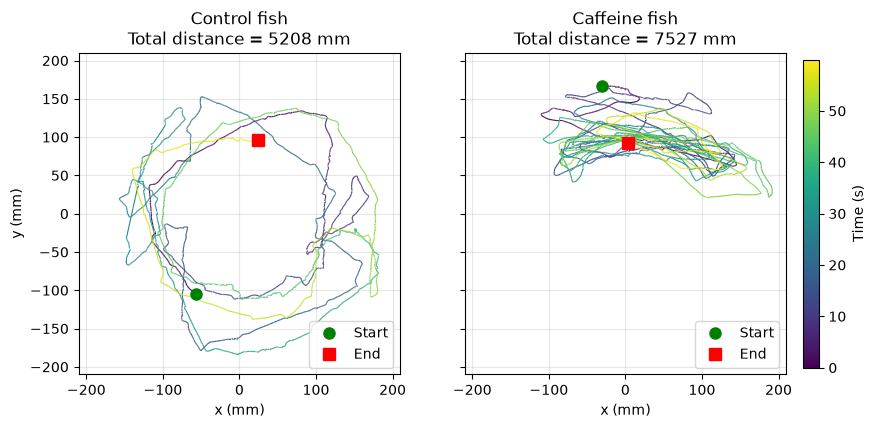

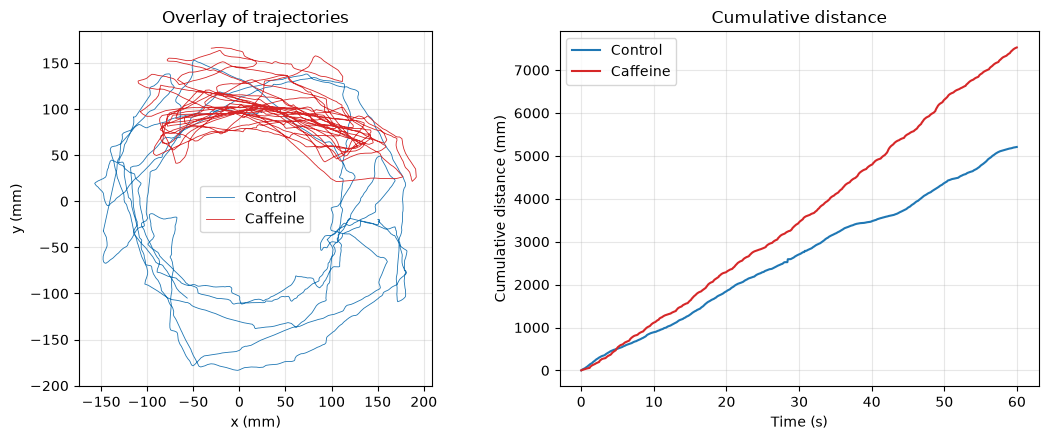

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from openpyxl import load_workbook

plt.style.use("default")

# ---------- Load data ----------
ws = load_workbook("Data.xlsx", read_only=True).active
rows = list(ws.iter_rows(min_row=3, values_only=True))
data = np.array(rows, dtype=float)[:, :5]
t, cx, cy, fx, fy = data.T

# ---------- Distances ----------
def steps(x, y):
    return np.hypot(np.diff(x), np.diff(y))

sc, sf = steps(cx, cy), steps(fx, fy)
d_ctrl, d_caf = sc.sum(), sf.sum()
dur = t[-1] - t[0]

# ---------- Results table ----------
line = "-" * 58
print(f"{'':28}{'Control fish':>15}{'Caffeine fish':>15}")
print(line)
print(f"{'Total distance (mm)':28}{d_ctrl:>15.1f}{d_caf:>15.1f}")
print(f"{'Total distance (cm)':28}{d_ctrl/10:>15.1f}{d_caf/10:>15.1f}")
print(f"{'Mean speed (mm/s)':28}{d_ctrl/dur:>15.1f}{d_caf/dur:>15.1f}")
print(f"{'Max step per 0.01 s (mm)':28}{sc.max():>15.1f}{sf.max():>15.1f}")
print(f"{'x range (mm)':28}{f'{cx.min():.0f} to {cx.max():.0f}':>15}{f'{fx.min():.0f} to {fx.max():.0f}':>15}")
print(f"{'y range (mm)':28}{f'{cy.min():.0f} to {cy.max():.0f}':>15}{f'{fy.min():.0f} to {fy.max():.0f}':>15}")
print(line)
print(f"Ratio (caffeine / control): {d_caf/d_ctrl:.2f}  ({100*(d_caf/d_ctrl-1):.0f}% farther)")

# ---------- Figure 1: trajectories colored by time ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (x, y, title, d) in zip(axes, [(cx, cy, "Control fish", d_ctrl),
                                       (fx, fy, "Caffeine fish", d_caf)]):
    pts = np.array([x, y]).T.reshape(-1, 1, 2)
    lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap="viridis", linewidth=0.8)
    lc.set_array(t[:-1])
    ax.add_collection(lc)
    ax.plot(x[0], y[0], "go", ms=8, label="Start")
    ax.plot(x[-1], y[-1], "rs", ms=8, label="End")
    ax.set_xlim(-210, 210); ax.set_ylim(-210, 210); ax.set_aspect("equal")
    ax.set_title(f"{title}\nTotal distance = {d:.0f} mm")
    ax.set_xlabel("x (mm)"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
axes[0].set_ylabel("y (mm)")
fig.colorbar(lc, ax=axes, shrink=0.8, pad=0.02).set_label("Time (s)")
plt.savefig("trajectories.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Figure 2: overlay + cumulative distance ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(cx, cy, lw=0.6, c="tab:blue", label="Control")
axes[0].plot(fx, fy, lw=0.6, c="tab:red", label="Caffeine")
axes[0].set_aspect("equal"); axes[0].set_xlabel("x (mm)"); axes[0].set_ylabel("y (mm)")
axes[0].set_title("Overlay of trajectories"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(t[1:], np.cumsum(sc), c="tab:blue", label="Control")
axes[1].plot(t[1:], np.cumsum(sf), c="tab:red", label="Caffeine")
axes[1].set_xlabel("Time (s)"); axes[1].set_ylabel("Cumulative distance (mm)")
axes[1].set_title("Cumulative distance"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("overlay_cumulative.png", dpi=200)
plt.show()